# 4. Hafta — Matplotlib ile Veriyi Görselleştirme

**BTP271 Uygulamalı Yapay Zeka** · Ön-Yüz Yazılım Geliştirme
Öğr. Gör. Çisem YAŞAR · cyasar@gelisim.edu.tr

---
## 🤔 Merak Sorusunun Cevabı
Sunumdaki soruyu hatırla: Ortalamaları ve korelasyonları **aynı** olan 4 veri seti (Anscombe, 1973) grafikte de aynı mı görünür?
Aşağıdaki hücreyi çalıştır ve cevabı gör.

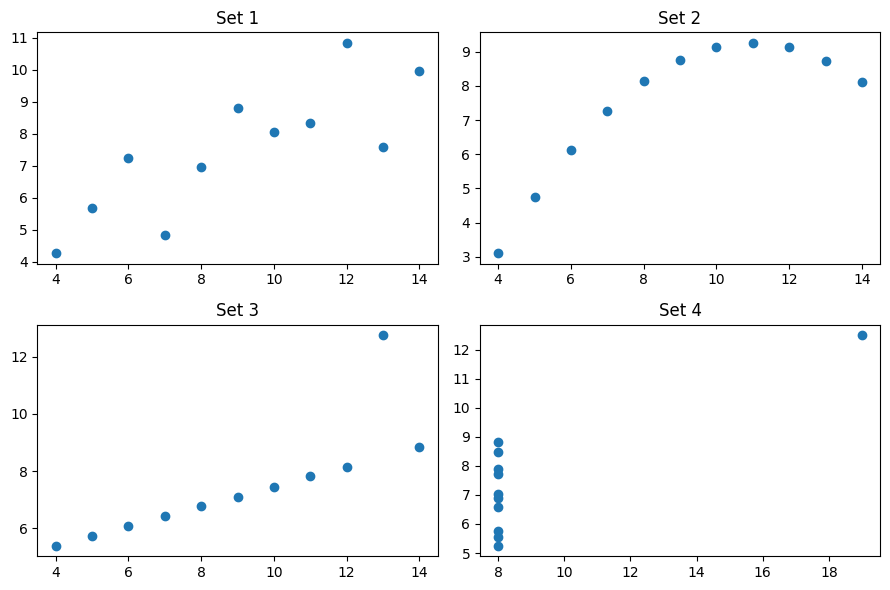

In [1]:
import matplotlib.pyplot as plt

x = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = {
    "Set 1": (x, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    "Set 2": (x, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    "Set 3": (x, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    "Set 4": ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
              [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}

fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, (ad, (xs, ys)) in zip(axes.flat, anscombe.items()):
    ax.scatter(xs, ys)
    ax.set_title(ad)
plt.tight_layout()
plt.show()

# Dört tamamen farklı hikâye: Set 1 dağınık ama doğrusal · Set 2 eğri ·
# Set 3 tek aykırı değer · Set 4 tek bir nokta tüm ilişkiyi yaratıyor.
# KURAL: Sadece sayılara bakmak yetmez; önce veriyi GÖR.

---
## 1. Matplotlib'e Giriş

**Matplotlib**, Python'un en yaygın grafik kütüphanesidir. İçindeki `pyplot` modülünü `plt` kısaltmasıyla kullanırız.
Her grafik aynı kalıbı izler: **çiz → etiketle → göster.**

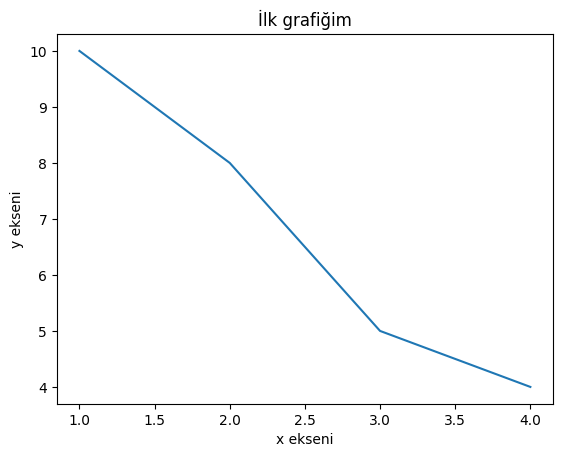

In [2]:
import matplotlib.pyplot as plt

plt.plot([1, 2, 3, 4], [10, 8, 5, 4])   # x değerleri, y değerleri
plt.title("İlk grafiğim")                # başlık
plt.xlabel("x ekseni")                   # yatay eksen etiketi
plt.ylabel("y ekseni")                   # dikey eksen etiketi
plt.show()                               # grafiği göster

---
## 2. Hangi soru, hangi grafik?

| Grafik | Komut | Hangi soruya cevap verir? |
|---|---|---|
| Çizgi | `plt.plot` | Zaman / adım boyunca **değişim** |
| Çubuk | `plt.bar`, `plt.barh` | **Kategorileri** karşılaştırma |
| Histogram | `plt.hist` | Değerler hangi aralıkta **yoğunlaşıyor** (dağılım)? |
| Saçılım | `plt.scatter` | İki sayısal değişken arasında **ilişki** var mı? |

---
## 3. Çizgi Grafiği — Model eğitimini izlemek

Bir model eğitilirken her turda (**epoch**) hatası (**kayıp / loss**) ölçülür. Kaybın düşmesi, modelin öğrendiğini gösterir.
Aynı eksene birden fazla çizgi çizebiliriz; `label` verip `plt.legend()` dersek hangi çizginin ne olduğu görünür.

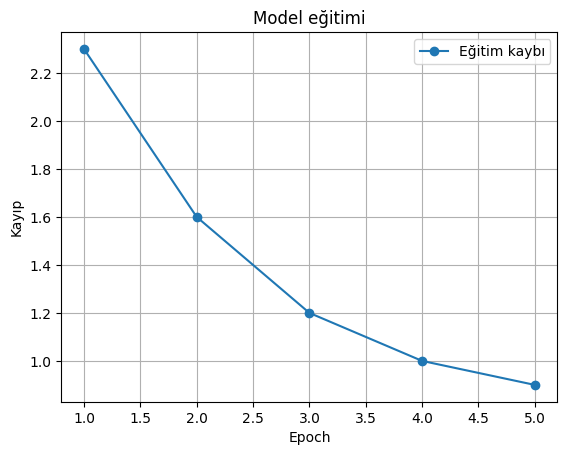

In [5]:
epoch = [1, 2, 3, 4, 5]
kayip = [2.3, 1.6, 1.2, 1.0, 0.9]

plt.plot(epoch, kayip, marker="o", label="Eğitim kaybı")
plt.title("Model eğitimi")
plt.xlabel("Epoch")
plt.ylabel("Kayıp")
plt.legend()     # label'ları gösteren kutu
plt.grid(True)   # arka plana ızgara
plt.show()

#### ✍️ Kendin Yaz — Eğitim ve doğrulama kaybı
Model eğitilirken iki kayıp izlenir: **eğitim** verisindeki kayıp ve modelin **hiç görmediği** doğrulama verisindeki kayıp.

1. İki kaybı **aynı grafikte** iki ayrı çizgi olarak çiz (`marker="o"` kullan).
2. Başlık, eksen etiketleri, `legend` ve `grid` ekle.
3. Grafiğe bakarak yorum satırındaki soruları cevapla.

In [ ]:
epochlar = list(range(1, 11))   # 1'den 10'a
egitim_kaybi     = [2.30, 1.80, 1.40, 1.10, 0.90, 0.75, 0.62, 0.52, 0.45, 0.40]
dogrulama_kaybi  = [2.40, 1.90, 1.50, 1.25, 1.10, 1.02, 1.00, 1.03, 1.09, 1.18]

# kodunu yaz


# Soru 1: Doğrulama kaybı hangi epoch'tan sonra artmaya başlıyor?
# Soru 2: Eğitim kaybı düşmeye devam ederken doğrulama kaybının artması ne anlama gelebilir?

---
## 4. Veri setimiz: Ev ilanları (geçen haftanın temiz tablosu)
Geçen hafta temizlediğimiz ev verisini bu hücre yeniden oluşturup aynı adımlarla temizliyor. Sadece çalıştır.

In [6]:
csv_metni = """ilan_id,semt,metrekare,oda_sayisi,bina_yasi,kat,fiyat
1,Avcılar,95,2,12,3,4250000
2,Avcılar,120,3,5,2,5900000
3,Beylikdüzü,140,3,3,7,6800000
4,Kadıköy,85,2,25,4,9500000
5,Beşiktaş,110,3,30,2,13200000
6,Esenyurt,100,2,2,5,3600000
7,Avcılar,150,4,,1,7100000
8,Kadıköy,130,3,15,3,14500000
9,Beylikdüzü,90,2,8,10,4100000
10,Esenyurt,135,3,4,8,4700000
11,Beşiktaş,75,1,40,1,
12,Avcılar,110,3,20,4,5200000
13,Kadıköy,160,4,,6,19800000
14,Beylikdüzü,180,4,1,3,8900000
15,Esenyurt,80,1,6,2,
9,Beylikdüzü,90,2,8,10,4100000
"""
with open("evler.csv", "w", encoding="utf-8") as f:
    f.write(csv_metni)

import pandas as pd

df = pd.read_csv("evler.csv")
temiz = df.drop_duplicates().dropna(subset=["fiyat"])
temiz = temiz.fillna({"bina_yasi": temiz["bina_yasi"].median()})
temiz["m2_fiyat"] = (temiz["fiyat"] / temiz["metrekare"]).round()

print(temiz.shape)
temiz.head()

(13, 8)


,ilan_id,semt,metrekare,oda_sayisi,bina_yasi,kat,fiyat,m2_fiyat
0,1,Avcılar,95,2,12.0,3,4250000.0,44737.0
1,2,Avcılar,120,3,5.0,2,5900000.0,49167.0
2,3,Beylikdüzü,140,3,3.0,7,6800000.0,48571.0
3,4,Kadıköy,85,2,25.0,4,9500000.0,111765.0
4,5,Beşiktaş,110,3,30.0,2,13200000.0,120000.0


---
## 5. Çubuk Grafiği — Kategorileri karşılaştırmak
`plt.bar(kategoriler, değerler)` dikey, `plt.barh(kategoriler, değerler)` yatay çubuk çizer.
Kategori isimleri uzunsa veya çok kategori varsa **yatay** çubuk daha okunaklıdır.

### Semtlere göre ilan sayısı
`value_counts()` sonucunu doğrudan çubuk grafiğine verebiliriz: `index` çubukların adları, `values` yükseklikleri olur.

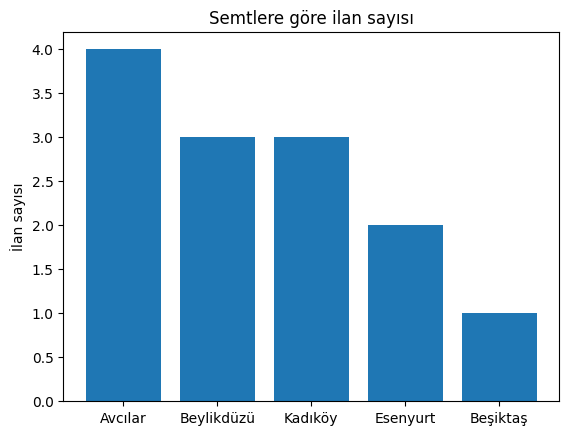

In [7]:
ilan_sayisi = temiz["semt"].value_counts()

plt.bar(ilan_sayisi.index, ilan_sayisi.values)
plt.title("Semtlere göre ilan sayısı")
plt.ylabel("İlan sayısı")
plt.show()

# 1) 5 çubuk (5 farklı semt)
# 2) Avcılar (4 ilan)
# 3) Beşiktaş (1 ilan; diğer ilanın fiyatı eksik olduğu için temizlikte silinmişti)

#### ✍️ Kendin Yaz — Hangi semt daha pahalı?
1. Her semt için **ortalama metrekare fiyatını** hesapla ve **küçükten büyüğe** sırala. Sonucu `semt_m2` değişkenine ata.
2. `plt.barh` ile **yatay** çubuk grafiği çiz.
3. Başlık ve `TL / m²` yazan bir x ekseni etiketi ekle.

In [ ]:
# kodunu yaz

In [ ]:
# 🧪 Test hücresi — değiştirme, sadece çalıştır
assert semt_m2.is_monotonic_increasing
assert semt_m2.index[-1] == "Beşiktaş"
assert semt_m2.index[0] == "Esenyurt"
print("✅ Tüm testler geçti!")

---
## 6. Histogram — Değerler nerede yoğunlaşıyor?
Histogram, sayısal değerleri **aralıklara (bins)** böler ve her aralıkta kaç değer olduğunu çubukla gösterir.
Çubuk grafiğinden farkı: x ekseni kategori değil, **sayı aralığıdır**; çubuklar bitişiktir.

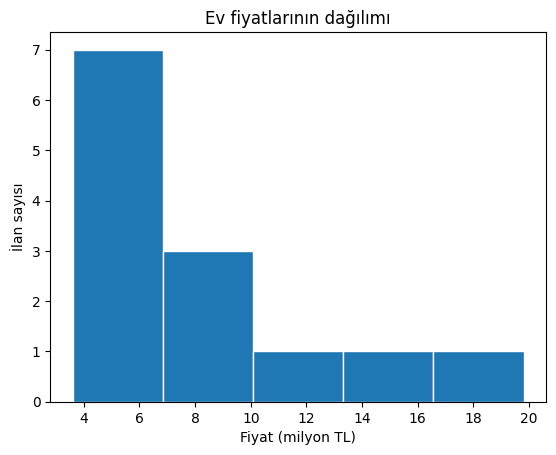

In [12]:
plt.hist(temiz["fiyat"] / 1_000_000, bins=5, edgecolor="white")
plt.title("Ev fiyatlarının dağılımı")
plt.xlabel("Fiyat (milyon TL)")
plt.ylabel("İlan sayısı")
plt.show()

#### ✍️ Kendin Yaz — Ortalama çizgisi
1. Fiyatları milyon TL'ye çevirip `fiyat_milyon` adında bir Series'e ata.
2. Ortalamasını `ortalama_milyon` değişkenine ata.
3. `bins=6` ile histogram çiz.
4. Ortalamayı dikey kesikli bir çizgiyle göster: `plt.axvline(ortalama_milyon, color="red", linestyle="--", label="Ortalama")`
5. Başlık, eksen etiketleri ve `legend` ekle.

Grafiğe bakıp cevapla: İlanların çoğu ortalamanın solunda mı, sağında mı? Neden?

In [ ]:
# kodunu yaz


# Cevabım:

In [ ]:
# 🧪 Test hücresi
assert abs(ortalama_milyon - 8.273) < 0.01
print("✅ Tüm testler geçti!")

---
## 7. Saçılım Grafiği — İki değişken arasında ilişki
Her ilan bir **nokta** olur: x ekseninde metrekaresi, y ekseninde fiyatı.

### Metrekare ve fiyat

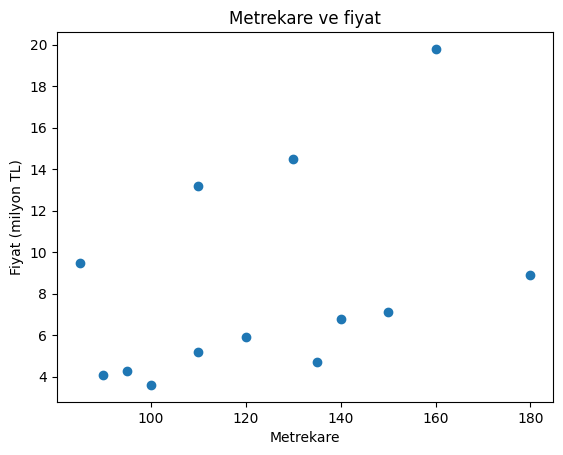

In [13]:
plt.scatter(temiz["metrekare"], temiz["fiyat"] / 1_000_000)
plt.title("Metrekare ve fiyat")
plt.xlabel("Metrekare")
plt.ylabel("Fiyat (milyon TL)")
plt.show()

# 1) Genel olarak YÜKSELİR: metrekare arttıkça fiyat artma eğiliminde (pozitif ilişki).
# 2) 160 m², 19.8 milyon TL → Kadıköy, 13 numaralı ilan.
# İlişki var ama kusursuz değil. 180 m²'lik Beylikdüzü evi,
# 130 m²'lik Kadıköy evinden ucuz. Demek ki fiyatı SEMT de etkiliyor.

#### ✍️ Kendin Yaz — Semtlere göre renkli saçılım
Yukarıdaki grafikte hangi noktanın hangi semte ait olduğu görünmüyor. Her semti **farklı renkte** çiz.

Geçen haftanın `groupby`'ı bir döngüde de kullanılabilir; her turda semt adını ve o semtin satırlarını verir:
```python
for semt, grup in temiz.groupby("semt"):
    # semt → "Avcılar", grup → sadece Avcılar satırları
```
1. Bu döngüyle her semt için ayrı bir `plt.scatter` çağır; `label=semt` ve `s=80` (nokta boyutu) ver.
2. Başlık, eksen etiketleri ve `legend` ekle.

In [ ]:
# kodunu yaz

---
## 8. Birden fazla grafik: `plt.subplots`
Birden fazla grafiği yan yana koymak için `fig, axes = plt.subplots(satır, sütun)` kullanılır.
`fig` resmin tamamı, `axes` içindeki grafik alanlarıdır. Her alana ayrı çizim yapılır.

| Tek grafik (`plt.`) | Grafik alanı (`ax.`) |
|---|---|
| `plt.title(...)` | `ax.set_title(...)` |
| `plt.xlabel(...)` | `ax.set_xlabel(...)` |
| `plt.ylabel(...)` | `ax.set_ylabel(...)` |
| `plt.plot / bar / hist / scatter` | `ax.plot / bar / hist / scatter` (aynı) |

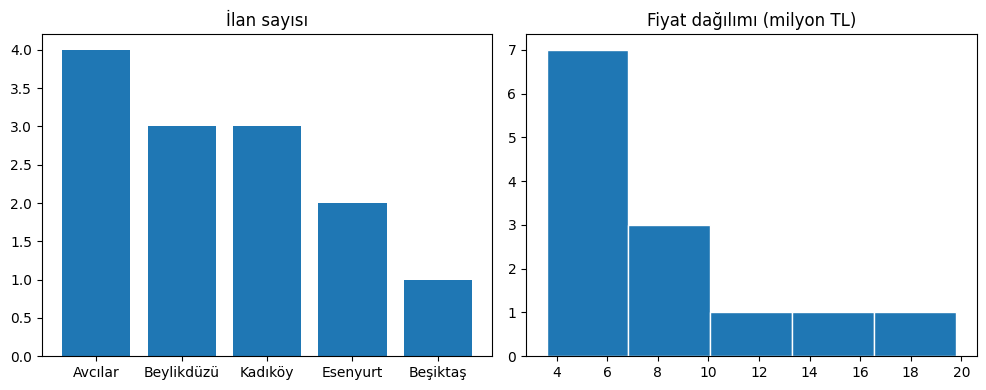

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))   # 1 satır, 2 sütun

axes[0].bar(ilan_sayisi.index, ilan_sayisi.values)
axes[0].set_title("İlan sayısı")

axes[1].hist(temiz["fiyat"] / 1_000_000, bins=5, edgecolor="white")
axes[1].set_title("Fiyat dağılımı (milyon TL)")

plt.tight_layout()   # grafiklerin birbirine taşmasını önler
plt.show()

### Pandas kısayolu
Pandas tabloları Matplotlib'i arka planda kendisi çağırabilir. Hızlı bir göz atmak için idealdir:

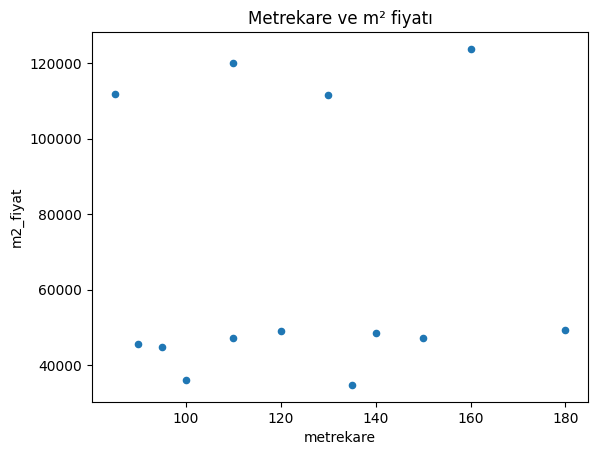

In [17]:
temiz.plot(kind="scatter", x="metrekare", y="m2_fiyat", title="Metrekare ve m² fiyatı")
plt.show()

---
## 9. Yeni bir veri seti: Iris
Iris, makine öğrenmesinin en klasik veri setidir: 3 farklı iris çiçeği türünden 150 çiçeğin yaprak ölçüleri.
7–8. haftalarda bu veriyle **çiçeğin türünü tahmin eden** bir model kuracağız. Bugün önce ona bakalım.
Scikit-learn kütüphanesinin içinde hazır gelir, internetten indirmeye gerek yoktur.

In [18]:
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)
df_iris = iris.frame
df_iris["tur"] = df_iris["target"].map({0: "setosa", 1: "versicolor", 2: "virginica"})

print(df_iris.shape)
print(df_iris["tur"].value_counts())
df_iris.head()

(150, 6)
tur
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,tur
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


#### ✍️ Kendin Yaz — Türler ayrışıyor mu?
1. `groupby("tur")` döngüsüyle her türü farklı renkte çiz:
   x ekseni `"petal length (cm)"` (taç yaprağı uzunluğu), y ekseni `"petal width (cm)"` (taç yaprağı genişliği).
2. Başlık, eksen etiketleri ve `legend` ekle.
3. Grafiğe bakıp cevapla: Hangi tür diğerlerinden **tamamen ayrı** duruyor? Hangi ikisi birbirine karışıyor?

In [ ]:
# kodunu yaz


# Cevabım:

---
## 10. Grafiği web için kaydetmek
Grafiği bir web sayfasında göstermek için resim dosyası olarak kaydederiz. `plt.savefig`, **`plt.show()`'dan önce** yazılmalıdır.

```html
<!-- Web sayfasında -->
<img src="grafik.png" alt="Semtlere göre ilan sayısı">
```

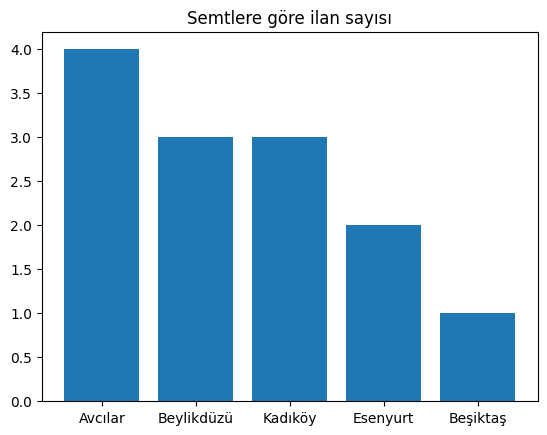

grafik.png kaydedildi — soldaki klasör simgesinden görebilirsin.


In [19]:
plt.bar(ilan_sayisi.index, ilan_sayisi.values)
plt.title("Semtlere göre ilan sayısı")
plt.savefig("grafik.png", dpi=150, bbox_inches="tight")   # dpi: çözünürlük
plt.show()
print("grafik.png kaydedildi — soldaki klasör simgesinden görebilirsin.")

---
## 🏁 Haftanın Mini Projesi — Emlak Raporu Paneli
Emlak sitesinin ana sayfasına konacak **4 grafikli bir panel** hazırla ve PNG olarak kaydet.

**Görevler:**
1. `fig, axes = plt.subplots(2, 2, figsize=(11, 8))` ile 2×2'lik bir düzen oluştur.
2. Dört alana şu grafikleri çiz, **her birine başlık** ver:
   - `axes[0, 0]` → Semtlere göre ilan sayısı (çubuk)
   - `axes[0, 1]` → Fiyat dağılımı, milyon TL (histogram)
   - `axes[1, 0]` → Metrekare ve fiyat (saçılım)
   - `axes[1, 1]` → Semtlere göre ortalama m² fiyatı (yatay çubuk)
3. Tüm panele bir üst başlık ekle: `fig.suptitle("İstanbul Emlak Raporu")`
4. `plt.tight_layout()` ile düzenle, `emlak_rapor.png` olarak kaydet ve göster.

In [ ]:
# kodunu yaz

In [ ]:
# 🧪 Test hücresi
import os
assert os.path.exists("emlak_rapor.png"), "emlak_rapor.png bulunamadı: savefig'i show'dan önce yazdın mı?"
assert len(fig.axes) == 4
assert all(ax.get_title() for ax in fig.axes), "Her grafiğin bir başlığı olmalı"
assert fig._suptitle is not None and fig._suptitle.get_text() != ""
print("✅ Tüm testler geçti! Tebrikler 🎉")